In [1]:
# Cell 1 — Data Generation & CSV Export
import numpy as np
import pandas as pd

# Fixed random seed for reproducible measurement noise.
rng = np.random.default_rng(42)

# ---------------------------------------------------------------------
# 1. Simulate a time-domain oscilloscope capture.
# ---------------------------------------------------------------------
sampling_rate_Hz = 500_000
capture_duration_s = 2e-3
signal_frequency_Hz = 2_000
signal_amplitude_V = 1.5  # Peak amplitude, not peak-to-peak.
dc_offset_V = 0.2
noise_std_V = 0.08

# Exclude the endpoint to preserve the exact sampling interval.
n_samples = int(round(sampling_rate_Hz * capture_duration_s))
time_s = np.arange(n_samples) / sampling_rate_Hz

voltage_ideal_V = (
    dc_offset_V
    + signal_amplitude_V * np.sin(2 * np.pi * signal_frequency_Hz * time_s)
)
voltage_measured_V = voltage_ideal_V + rng.normal(
    loc=0.0, scale=noise_std_V, size=n_samples
)

time_domain_data = pd.DataFrame({
    "time_s": time_s,
    "voltage_measured_V": voltage_measured_V,
    "voltage_ideal_V": voltage_ideal_V,
})
time_domain_data.to_csv("time_domain_signal.csv", index=False)

# ---------------------------------------------------------------------
# 2. Simulate an AC sweep of a first-order low-pass system.
# ---------------------------------------------------------------------
frequency_Hz = np.logspace(2, 6, num=60)
dc_gain_V_per_V = 20.0
cutoff_frequency_Hz = 10_000.0
vin_pp_V = np.full(frequency_Hz.shape, 0.1)

# H(jf) = A0 / (1 + j*f/fc); magnitude = A0 / sqrt(1 + (f/fc)^2).
gain_magnitude = dc_gain_V_per_V / np.sqrt(
    1.0 + (frequency_Hz / cutoff_frequency_Hz) ** 2
)
vout_pp_ideal_V = vin_pp_V * gain_magnitude

# Multiplicative Gaussian noise: zero mean and 2% relative standard deviation.
relative_measurement_noise = rng.normal(
    loc=0.0, scale=0.02, size=frequency_Hz.size
)
vout_pp_measured_V = vout_pp_ideal_V * (1.0 + relative_measurement_noise)

ac_sweep_data = pd.DataFrame({
    "frequency_Hz": frequency_Hz,
    "vin_pp_V": vin_pp_V,
    "vout_pp_measured_V": vout_pp_measured_V,
})
ac_sweep_data.to_csv("ac_sweep_data.csv", index=False)

# Confirm export and preview both datasets.
print(
    f"Exported time_domain_signal.csv ({len(time_domain_data)} samples) "
    f"and ac_sweep_data.csv ({len(ac_sweep_data)} frequency points)."
)
print("\nTime-domain data — first 5 rows:")
print(time_domain_data.head(5).to_string(index=False))
print("\nAC sweep data — first 5 rows:")
print(ac_sweep_data.head(5).to_string(index=False))

Exported time_domain_signal.csv (1000 samples) and ac_sweep_data.csv (60 frequency points).

Time-domain data — first 5 rows:
  time_s  voltage_measured_V  voltage_ideal_V
0.000000            0.224377         0.200000
0.000002            0.154496         0.237695
0.000004            0.335403         0.275366
0.000006            0.388235         0.312990
0.000008            0.194460         0.350543

AC sweep data — first 5 rows:
 frequency_Hz  vin_pp_V  vout_pp_measured_V
   100.000000       0.1            1.997529
   116.895182       0.1            1.970694
   136.644835       0.1            1.983236
   159.731228       0.1            2.025098
   186.718109       0.1            1.999771


Inferred sampling rate: 500,000.00 Hz

Signal metrics (all voltages in V):
             V_dc     V_pp  V_rms_ac
Signal                              
Raw      0.197689 3.369052  1.064758
Filtered 0.198126 3.048334  1.061936
Ideal    0.200000 2.999763  1.060660

Estimated SNR (filtered AC / residual): 22.89 dB
Note: residual-based SNR excludes noise retained in the passband.


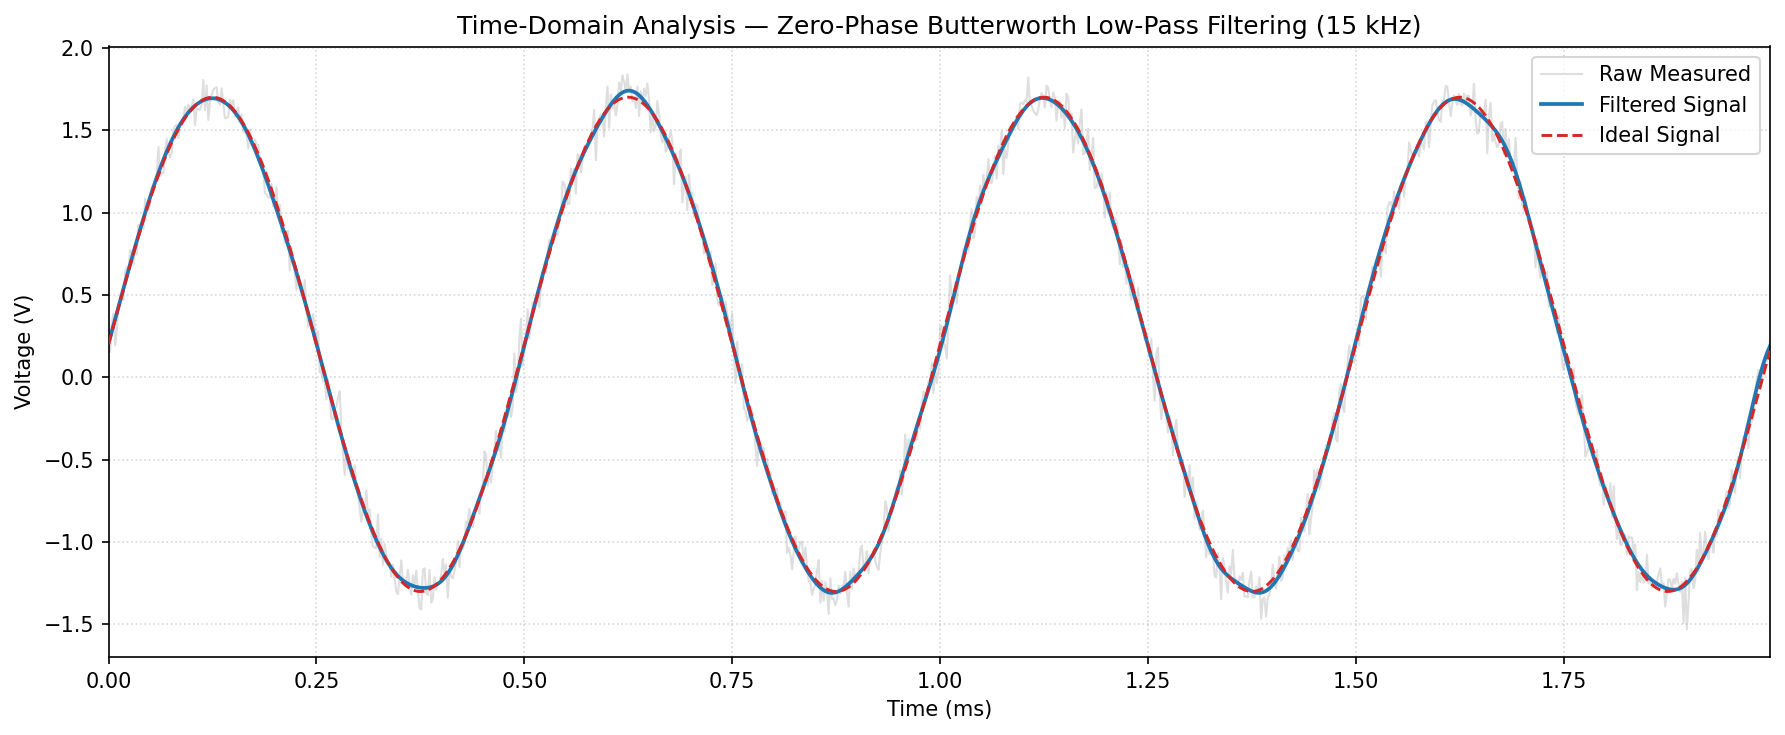

In [2]:
# Cell 2 — Time-Domain Signal Processing, Filtering & Plotting
import numpy as np
import pandas as pd
from scipy.signal import butter, filtfilt
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------
# 1. Load the capture and infer the sampling rate from its timestamps.
# ---------------------------------------------------------------------
data = pd.read_csv("time_domain_signal.csv")
t = data["time_s"].to_numpy()
voltage_measured_V = data["voltage_measured_V"].to_numpy()
voltage_ideal_V = data["voltage_ideal_V"].to_numpy()

fs = 1.0 / np.mean(np.diff(t))

# ---------------------------------------------------------------------
# 2. Apply a fourth-order Butterworth low-pass filter in both directions.
# ---------------------------------------------------------------------
filter_order = 4
cutoff_frequency_Hz = 15_000.0

if not 0.0 < cutoff_frequency_Hz < fs / 2.0:
    raise ValueError("The cutoff frequency must lie below the Nyquist frequency.")

b, a = butter(
    N=filter_order,
    Wn=cutoff_frequency_Hz,
    btype="lowpass",
    fs=fs,
)
# Forward-backward filtering removes phase delay and squares the magnitude
# response of the designed fourth-order filter. Edge transients may remain.
voltage_filtered_V = filtfilt(b, a, voltage_measured_V)

# ---------------------------------------------------------------------
# 3. Define voltage metrics and compare all three signals.
# ---------------------------------------------------------------------
def compute_signal_metrics(v):
    """Return DC offset, peak-to-peak voltage, and DC-removed RMS in volts."""
    v = np.asarray(v, dtype=float)
    V_dc = np.mean(v)
    return {
        "V_dc": V_dc,
        "V_pp": np.max(v) - np.min(v),
        "V_rms_ac": np.sqrt(np.mean((v - V_dc) ** 2)),
    }


metrics_table = pd.DataFrame.from_dict(
    {
        "Raw": compute_signal_metrics(voltage_measured_V),
        "Filtered": compute_signal_metrics(voltage_filtered_V),
        "Ideal": compute_signal_metrics(voltage_ideal_V),
    },
    orient="index",
)
metrics_table.index.name = "Signal"

# Estimate AC signal power from the filtered waveform and noise power from
# the raw-minus-filtered residual. This is a filter-dependent estimate:
# noise retained in the passband is not captured by the residual.
noise_residual_V = voltage_measured_V - voltage_filtered_V
signal_power_V2 = metrics_table.loc["Filtered", "V_rms_ac"] ** 2
noise_power_V2 = np.mean(noise_residual_V ** 2)

if noise_power_V2 == 0.0:
    estimated_snr_dB = np.inf if signal_power_V2 > 0.0 else np.nan
elif signal_power_V2 == 0.0:
    estimated_snr_dB = -np.inf
else:
    estimated_snr_dB = 10.0 * np.log10(signal_power_V2 / noise_power_V2)

print(f"Inferred sampling rate: {fs:,.2f} Hz")
print("\nSignal metrics (all voltages in V):")
print(metrics_table.to_string(float_format=lambda value: f"{value:.6f}"))
print(f"\nEstimated SNR (filtered AC / residual): {estimated_snr_dB:.2f} dB")
print("Note: residual-based SNR excludes noise retained in the passband.")

# ---------------------------------------------------------------------
# 4. Plot the capture, filtered waveform, and ideal reference.
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 5), dpi=150)

ax.plot(
    t * 1e3, voltage_measured_V,
    color="lightgray", alpha=0.75, linewidth=1.0,
    label="Raw Measured", zorder=1,
)
ax.plot(
    t * 1e3, voltage_filtered_V,
    color="tab:blue", linestyle="-", linewidth=1.8,
    label="Filtered Signal", zorder=2,
)
ax.plot(
    t * 1e3, voltage_ideal_V,
    color="tab:red", linestyle="--", linewidth=1.4,
    label="Ideal Signal", zorder=3,
)

ax.set(
    xlabel="Time (ms)",
    ylabel="Voltage (V)",
    title="Time-Domain Analysis — Zero-Phase Butterworth Low-Pass Filtering (15 kHz)",
    xlim=(t[0] * 1e3, t[-1] * 1e3),
)
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig("time_domain_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

Frequency Response Analysis
----------------------------------------------------------------
Measured passband gain (first 5 points): 26.000 dB (19.9518 V/V)
Half-power threshold:                     22.989 dB
Interpolated -3 dB cutoff:                 10,488.01 Hz (10.4880 kHz)
Curve-fitted cutoff:                       10,064.76 Hz (10.0648 kHz)
Fitted passband gain:                     25.993 dB

The interpolated cutoff uses the measured passband; the fitted cutoff is relative to the fitted passband.


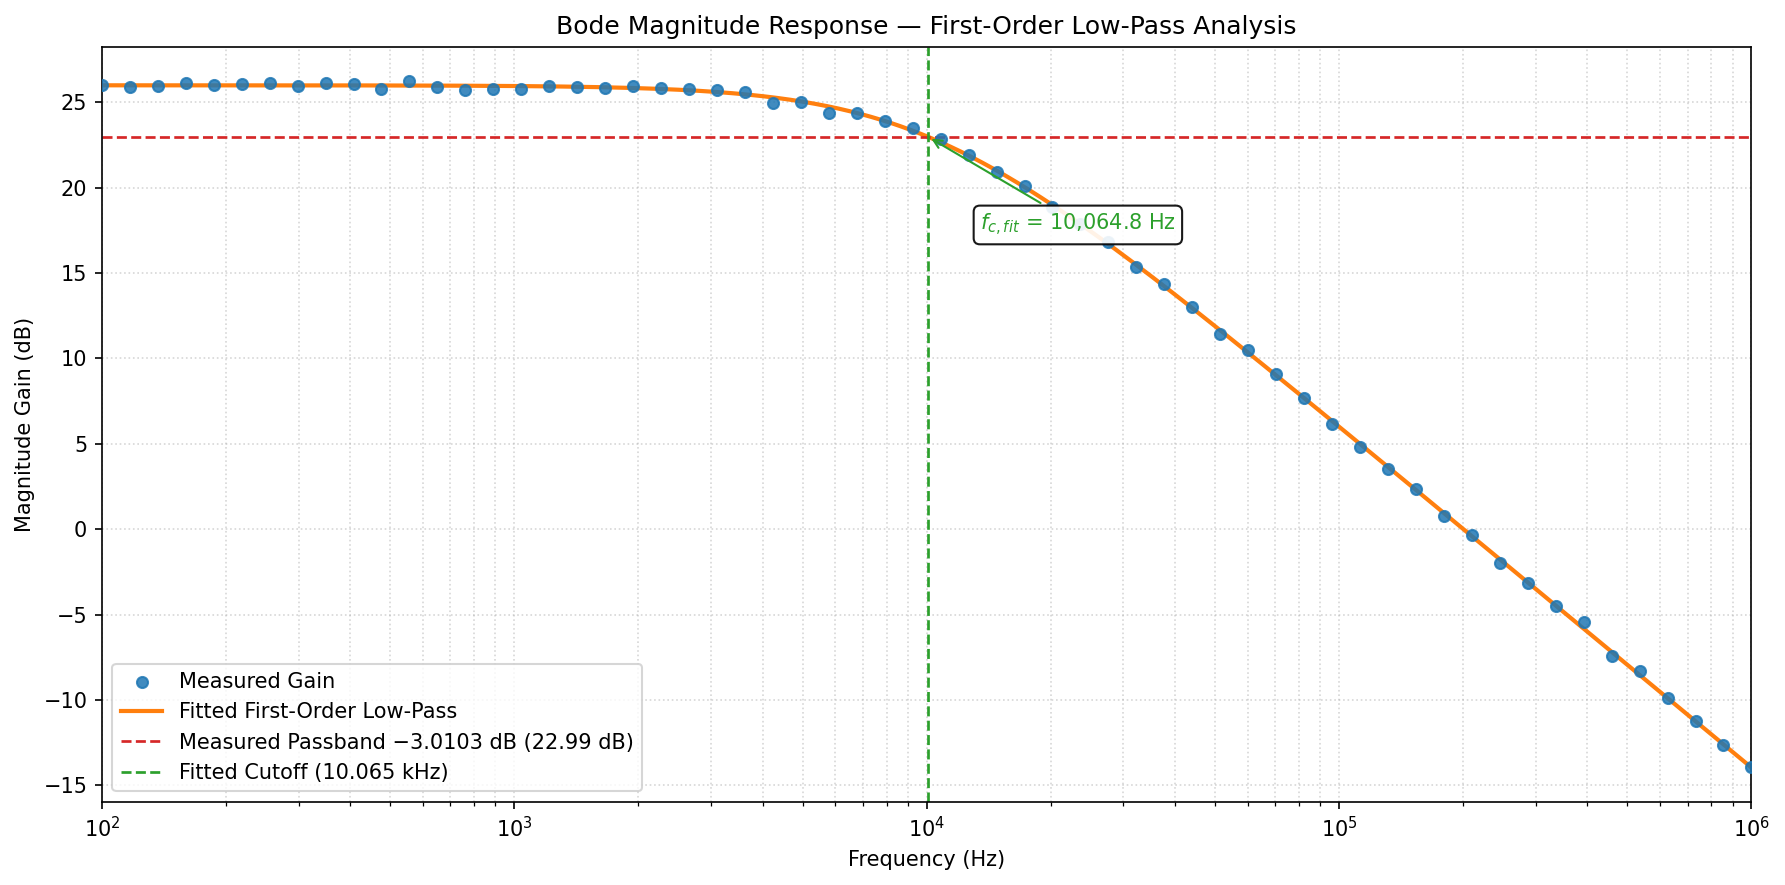

In [3]:
# Cell 3 — Frequency Response Analysis & Automatic -3 dB Cutoff Detection
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------
# 1. Load and sort the sweep by ascending frequency.
# ---------------------------------------------------------------------
sweep = pd.read_csv("ac_sweep_data.csv").sort_values("frequency_Hz")
frequency_Hz = sweep["frequency_Hz"].to_numpy()
vin_pp_V = sweep["vin_pp_V"].to_numpy()
vout_pp_measured_V = sweep["vout_pp_measured_V"].to_numpy()

if (
    frequency_Hz.size < 5
    or not np.all(np.isfinite(sweep[
        ["frequency_Hz", "vin_pp_V", "vout_pp_measured_V"]
    ].to_numpy()))
    or np.any(frequency_Hz <= 0)
    or np.any(np.diff(frequency_Hz) <= 0)
    or np.any(vin_pp_V <= 0)
    or np.any(vout_pp_measured_V <= 0)
):
    raise ValueError(
        "At least five finite sweep points with positive voltages and "
        "strictly increasing positive frequencies are required."
    )

gain_linear = vout_pp_measured_V / vin_pp_V
gain_db = 20.0 * np.log10(gain_linear)

# ---------------------------------------------------------------------
# 2. Estimate passband gain and interpolate the half-power cutoff.
# ---------------------------------------------------------------------
gain_passband_db = np.mean(gain_db[:5])
# Converting the mean dB gain gives the geometric mean linear gain.
gain_passband_linear = 10.0 ** (gain_passband_db / 20.0)
threshold_db = gain_passband_db - 20.0 * np.log10(np.sqrt(2.0))

# Measurement noise can make the full gain array nonmonotonic. Locate the
# first downward threshold crossing, then interpolate only its two endpoints.
crossing_indices = np.flatnonzero(
    (gain_db[:-1] >= threshold_db) & (gain_db[1:] < threshold_db)
)
if crossing_indices.size == 0:
    raise ValueError(
        "No downward -3 dB crossing was found within the measured sweep."
    )

i = crossing_indices[0]
# Reverse the decreasing gain endpoints so np.interp receives increasing xp.
log_fc_interp = np.interp(
    threshold_db,
    gain_db[i:i + 2][::-1],
    np.log10(frequency_Hz[i:i + 2])[::-1],
)
fc_interp = 10.0 ** log_fc_interp

# ---------------------------------------------------------------------
# 3. Fit a first-order low-pass magnitude model to the linear gain.
# ---------------------------------------------------------------------
def lowpass_magnitude(f, A0, fc):
    """Return linear voltage gain for a first-order low-pass system."""
    return A0 / np.sqrt(1.0 + (f / fc) ** 2)


fit_parameters, fit_covariance = curve_fit(
    lowpass_magnitude,
    frequency_Hz,
    gain_linear,
    p0=(gain_passband_linear, fc_interp),
    bounds=([0.0, np.finfo(float).eps], [np.inf, np.inf]),
    maxfev=10_000,
)
A0_fit, fc_fit = fit_parameters
A0_fit_db = 20.0 * np.log10(A0_fit)

# ---------------------------------------------------------------------
# 4. Print measured and fitted frequency-response parameters.
# ---------------------------------------------------------------------
print("Frequency Response Analysis")
print("-" * 64)
print(
    f"Measured passband gain (first 5 points): "
    f"{gain_passband_db:.3f} dB ({gain_passband_linear:.4f} V/V)"
)
print(f"Half-power threshold:                     {threshold_db:.3f} dB")
print(
    f"Interpolated -3 dB cutoff:                 "
    f"{fc_interp:,.2f} Hz ({fc_interp / 1e3:.4f} kHz)"
)
print(
    f"Curve-fitted cutoff:                       "
    f"{fc_fit:,.2f} Hz ({fc_fit / 1e3:.4f} kHz)"
)
print(f"Fitted passband gain:                     {A0_fit_db:.3f} dB")
print(
    "\nThe interpolated cutoff uses the measured passband; the fitted cutoff "
    "is relative to the fitted passband."
)

# ---------------------------------------------------------------------
# 5. Plot the measured magnitude response and fitted low-pass model.
# ---------------------------------------------------------------------
frequency_plot_Hz = np.logspace(
    np.log10(frequency_Hz.min()),
    np.log10(frequency_Hz.max()),
    1000,
)
gain_fit_db = 20.0 * np.log10(
    lowpass_magnitude(frequency_plot_Hz, A0_fit, fc_fit)
)
gain_at_fc_fit_db = A0_fit_db - 20.0 * np.log10(np.sqrt(2.0))

fig, ax = plt.subplots(figsize=(12, 6), dpi=150)
ax.set_xscale("log")

ax.scatter(
    frequency_Hz, gain_db,
    color="tab:blue", s=28, alpha=0.85,
    label="Measured Gain", zorder=3,
)
ax.plot(
    frequency_plot_Hz, gain_fit_db,
    color="tab:orange", linewidth=2.0,
    label="Fitted First-Order Low-Pass",
)
ax.axhline(
    threshold_db,
    color="tab:red", linestyle="--", linewidth=1.3,
    label=f"Measured Passband −3.0103 dB ({threshold_db:.2f} dB)",
)
ax.axvline(
    fc_fit,
    color="tab:green", linestyle="--", linewidth=1.3,
    label=f"Fitted Cutoff ({fc_fit / 1e3:.3f} kHz)",
)
ax.annotate(
    f"$f_{{c,fit}}$ = {fc_fit:,.1f} Hz",
    xy=(fc_fit, gain_at_fc_fit_db),
    xytext=(25, -45),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "tab:green"},
    bbox={"boxstyle": "round,pad=0.3", "fc": "white", "alpha": 0.9},
    color="tab:green",
)

ax.set(
    xlabel="Frequency (Hz)",
    ylabel="Magnitude Gain (dB)",
    title="Bode Magnitude Response — First-Order Low-Pass Analysis",
    xlim=(frequency_Hz.min(), frequency_Hz.max()),
)
ax.grid(True, which="both", linestyle=":", alpha=0.5)
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig("bode_response_plot.png", dpi=300, bbox_inches="tight")
plt.show()

In [4]:
# Cell 4 — Executive Engineering Test Report & File Export
from pathlib import Path
import numpy as np

# ---------------------------------------------------------------------
# 1. Collect extracted metrics and define nominal reference parameters.
# ---------------------------------------------------------------------
V_pp_nominal = 3.0
V_rms_nominal = 1.5 / np.sqrt(2.0)
fc_nominal = 10_000.0
A0_nominal = 20.0
A0_nominal_db = 20.0 * np.log10(A0_nominal)

raw_metrics = metrics_table.loc["Raw"]
filtered_metrics = metrics_table.loc["Filtered"]


def relative_error_percent(measured, nominal):
    """Return signed relative error; positive values indicate overestimation."""
    return 100.0 * (measured - nominal) / nominal


raw_vpp_error = relative_error_percent(raw_metrics["V_pp"], V_pp_nominal)
filtered_vpp_error = relative_error_percent(
    filtered_metrics["V_pp"], V_pp_nominal
)
raw_rms_error = relative_error_percent(raw_metrics["V_rms_ac"], V_rms_nominal)
filtered_rms_error = relative_error_percent(
    filtered_metrics["V_rms_ac"], V_rms_nominal
)
fc_interp_error = relative_error_percent(fc_interp, fc_nominal)
fc_fit_error = relative_error_percent(fc_fit, fc_nominal)
passband_error = relative_error_percent(gain_passband_linear, A0_nominal)
fitted_gain_error = relative_error_percent(A0_fit, A0_nominal)

# ---------------------------------------------------------------------
# 2. Construct an ASCII report using the existing analysis results.
# ---------------------------------------------------------------------
report = f"""\
==============================================================================
                 AUTOMATED OSCILLOSCOPE ENGINEERING TEST REPORT
==============================================================================
TEST SCOPE
  Simulated time-domain capture and first-order low-pass frequency response.
  Relative error (%) = 100 * (measured - nominal) / nominal.
  Errors are signed. Gain percentage errors use linear V/V, not dB.

1. NOMINAL REFERENCES
------------------------------------------------------------------------------
  Signal peak-to-peak voltage : {V_pp_nominal:.6f} V
  Signal AC RMS voltage      : {V_rms_nominal:.6f} V
  Low-pass cutoff frequency  : {fc_nominal:,.2f} Hz
  Low-pass DC gain           : {A0_nominal:.6f} V/V ({A0_nominal_db:.4f} dB)

2. TIME-DOMAIN RESULTS
------------------------------------------------------------------------------
  Inferred sampling rate    : {fs:,.2f} Hz ({fs / 1e3:.3f} kHz)
  Processing                : 4th-order Butterworth design, 15 kHz cutoff
                              Forward-backward, zero-phase filtering

  Metric                         Raw Measured          Filtered
  --------------------------------------------------------------------------
  DC offset, V_dc (V)             {raw_metrics["V_dc"]:>12.6f}      {filtered_metrics["V_dc"]:>12.6f}
  Peak-to-peak, V_pp (V)          {raw_metrics["V_pp"]:>12.6f}      {filtered_metrics["V_pp"]:>12.6f}
  AC RMS, V_rms_ac (V)            {raw_metrics["V_rms_ac"]:>12.6f}      {filtered_metrics["V_rms_ac"]:>12.6f}
  V_pp relative error (%)         {raw_vpp_error:>+12.3f}      {filtered_vpp_error:>+12.3f}
  AC RMS relative error (%)       {raw_rms_error:>+12.3f}      {filtered_rms_error:>+12.3f}

  Estimated SNR             : {estimated_snr_dB:.3f} dB
  SNR definition            : 10*log10(filtered AC power / residual power)
  Noise residual            : Raw measured voltage - filtered voltage

3. FREQUENCY-RESPONSE RESULTS
------------------------------------------------------------------------------
  Measured passband gain    : {gain_passband_db:.4f} dB
                              {gain_passband_linear:.6f} V/V
  Passband gain error       : {passband_error:+.3f} %
  Half-power threshold      : {threshold_db:.4f} dB
  Interpolated cutoff       : {fc_interp:,.3f} Hz ({fc_interp / 1e3:.6f} kHz)
  Interpolated cutoff error : {fc_interp_error:+.3f} %

  Curve-fitted cutoff       : {fc_fit:,.3f} Hz ({fc_fit / 1e3:.6f} kHz)
  Curve-fitted cutoff error : {fc_fit_error:+.3f} %
  Fitted passband gain      : {A0_fit_db:.4f} dB
                              {A0_fit:.6f} V/V
  Fitted gain error         : {fitted_gain_error:+.3f} %

4. ENGINEERING INTERPRETATION AND LIMITATIONS
------------------------------------------------------------------------------
  - Measured passband gain is the mean dB gain of the five lowest-frequency
    points; its V/V equivalent is their geometric mean linear gain.
  - The half-power level is exactly 20*log10(sqrt(2)) below the passband,
    approximately 3.0103 dB, rather than exactly 3.0000 dB.
  - Interpolated cutoff uses the measured passband and local log-frequency
    interpolation. Fitted cutoff is relative to the fitted passband.
  - Residual-based SNR excludes noise retained in the filter passband and
    can include signal distortion and edge transients.
  - Peak-to-peak metrics are sensitive to noise and extreme samples.
  - Forward-backward filtering squares the designed magnitude response.
  - No acceptance tolerances were specified; no PASS/FAIL judgment is made.
==============================================================================
"""

# Print and save the same ASCII report.
print(report)
report_path = Path("test_report.txt")
report_path.write_text(report, encoding="ascii")

# ---------------------------------------------------------------------
# 3. Verify that every expected output exists and contains data.
# ---------------------------------------------------------------------
expected_files = [
    "time_domain_signal.csv",
    "ac_sweep_data.csv",
    "time_domain_analysis.png",
    "bode_response_plot.png",
    "test_report.txt",
]

print("OUTPUT FILE VERIFICATION")
print("-" * 78)
print(f"{'File':<34} {'Status':<20} {'Size (bytes)':>14}")
print("-" * 78)

all_outputs_valid = True
for filename in expected_files:
    path = Path(filename)
    if not path.is_file():
        status, size = "MISSING / NOT FILE", None
        all_outputs_valid = False
    else:
        size = path.stat().st_size
        status = "OK - NON-EMPTY" if size > 0 else "EMPTY"
        if size == 0:
            all_outputs_valid = False

    size_text = f"{size:,}" if size is not None else "-"
    print(f"{filename:<34} {status:<20} {size_text:>14}")

print("-" * 78)
print(
    "All expected output files exist and are non-empty."
    if all_outputs_valid
    else "WARNING: Missing or empty output files detected; rerun the relevant cells."
)

                 AUTOMATED OSCILLOSCOPE ENGINEERING TEST REPORT
TEST SCOPE
  Simulated time-domain capture and first-order low-pass frequency response.
  Relative error (%) = 100 * (measured - nominal) / nominal.
  Errors are signed. Gain percentage errors use linear V/V, not dB.

1. NOMINAL REFERENCES
------------------------------------------------------------------------------
  Signal peak-to-peak voltage : 3.000000 V
  Signal AC RMS voltage      : 1.060660 V
  Low-pass cutoff frequency  : 10,000.00 Hz
  Low-pass DC gain           : 20.000000 V/V (26.0206 dB)

2. TIME-DOMAIN RESULTS
------------------------------------------------------------------------------
  Inferred sampling rate    : 500,000.00 Hz (500.000 kHz)
  Processing                : 4th-order Butterworth design, 15 kHz cutoff
                              Forward-backward, zero-phase filtering

  Metric                         Raw Measured          Filtered
  -----------------------------------------------------------